In [1]:
# ============================================================================
# COMPARISON STUDY: Multi-Task Learning with mBERT for Citizen Complaint 
# Categorization and Severity Prediction
# ============================================================================
# CELL 1: IMPORTS AND SETUP

import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, 
    precision_recall_fscore_support,
    confusion_matrix, 
    classification_report,
    f1_score,
    roc_auc_score
)
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from scipy import stats
from scipy.stats import ttest_ind, f_oneway

import seaborn as sns
import matplotlib.pyplot as plt
import pickle
import logging
from datetime import datetime

# Set style for IEEE Access quality figures
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

print("✅ All imports completed successfully")
print(f"PyTorch version: {torch.__version__}")
print(f"Transformers version: {__import__('transformers').__version__}")

✅ All imports completed successfully
PyTorch version: 2.5.1+cu121
Transformers version: 4.51.3


In [ ]:
# ============================================================================
# CELL 2: CONFIGURATION - mBERT
# ============================================================================

class Config:
    """Configuration settings for the project - mBERT Version"""
    
    # Model paths - mBERT
    MBERT_PATH = "bert-base-multilingual-cased"  # mBERT model
    
    # Training params
    MAX_LENGTH = 128
    BATCH_SIZE = 32
    EPOCHS = 12
    LEARNING_RATE = 2e-5
    DROPOUT = 0.3
    WEIGHT_DECAY = 0.01
    
    # Data paths
    TRAIN_PATH = "Original Dataset/dataset/train/train.csv"
    DEV_PATH = "Original Dataset/dataset//dev/dev.csv"
    TEST_PATH = "Original Dataset/dataset//test/test.csv"
    
    # Output
    OUTPUT_DIR = "results_mbert"
    MODEL_DIR = "models_mbert"
    VISUALIZATION_DIR = "visualizations_mbert"
    
    # HuggingFace token (replace with your token)
    HF_TOKEN = os.getenv("HF_TOKEN")
    
    # Device
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # Random seed for reproducibility
    SEED = 42

# Create directories
os.makedirs(Config.OUTPUT_DIR, exist_ok=True)
os.makedirs(Config.MODEL_DIR, exist_ok=True)
os.makedirs(Config.VISUALIZATION_DIR, exist_ok=True)

print(f"Device: {Config.DEVICE}")
print(f"Output directory: {Config.OUTPUT_DIR}")
print("✅ Configuration loaded successfully")

Device: cuda
Output directory: results_mbert
✅ Configuration loaded successfully


In [3]:
# ============================================================================
# CELL 3: DATA PREPROCESSOR WITH SENTIMENT ANALYSIS
# ============================================================================

class DataPreprocessor:
    """Data preprocessing with sentiment analysis for severity detection"""
    
    def __init__(self):
        self.le_primary = LabelEncoder()
        self.le_subcat = LabelEncoder()
        self.le_severity = LabelEncoder()
        self.scaler = StandardScaler()
        self.sentiment_weights = None
        
    def load_data(self):
        """Load and combine datasets"""
        print("Loading data...")
        train_df = pd.read_csv(Config.TRAIN_PATH)
        dev_df = pd.read_csv(Config.DEV_PATH)
        test_df = pd.read_csv(Config.TEST_PATH)
        
        print(f"Train samples: {len(train_df)}")
        print(f"Dev samples: {len(dev_df)}")
        print(f"Test samples: {len(test_df)}")
        
        # Combine for consistent encoding
        full_df = pd.concat([train_df, dev_df, test_df], ignore_index=True)
        return train_df, dev_df, test_df, full_df
    
    def preprocess_text(self, df):
        """Combine text fields and handle missing values"""
        df["text"] = (
            df["complaint_title"].astype(str) + " " +
            df["text_en"].astype(str) + " " +
            df["Hindi"].astype(str) + " " +
            df["Hinglish"].astype(str)
        )
        
        df = df.dropna(subset=[
            "text", "category_primary", 
            "category_secondary", "severity"
        ])
        
        return df.reset_index(drop=True)
    
    def compute_sentiment_score(self, text):
        """
        Compute sentiment score for severity enhancement
        Returns: value between -1 (negative) and 1 (positive)
        """
        # Comprehensive negative keywords
        negative_words = {
            'emergency': 3, 'urgent': 3, 'critical': 3, 'immediately': 2,
            'asap': 2, 'urgently': 2, 'serious': 2, 'severe': 2,
            'dangerous': 2, 'threat': 2, 'risk': 2, 'panic': 2,
            'crisis': 3, 'problem': 1, 'issue': 1, 'complaint': 1,
            'not working': 2, 'broken': 2, 'damage': 2, 'accident': 2,
            'hurt': 2, 'injured': 2, 'unsafe': 2, 'hazard': 2,
            'frustrated': 1, 'angry': 1, 'disgusting': 1, 'terrible': 1,
            'worst': 1, 'bad': 1, 'awful': 1, 'horrible': 1,
            'stuck': 1, 'trapped': 1, 'blocked': 1, 'flood': 2,
            'leakage': 2, 'overflow': 2, 'smell': 1, 'stink': 1,
            'rotten': 1, 'garbage': 1, 'waste': 1, 'unhygienic': 1,
            'pothole': 1, 'crack': 1, 'uneven': 1, 'danger': 2
        }
        
        positive_words = {
            'good': 1, 'great': 1, 'excellent': 2, 'satisfied': 2,
            'happy': 1, 'thankful': 1, 'grateful': 1, 'appreciate': 1,
            'well': 1, 'nice': 1, 'better': 1, 'improved': 1,
            'fixed': 1, 'resolved': 1, 'working': 1, 'fine': 1
        }
        
        text_lower = text.lower()
        
        # Calculate scores with weights
        negative_score = sum(weight for word, weight in negative_words.items() 
                           if word in text_lower)
        positive_score = sum(weight for word, weight in positive_words.items() 
                           if word in text_lower)
        
        # Normalize sentiment score between -1 and 1
        total_score = negative_score + positive_score
        if total_score == 0:
            return 0.0
        
        sentiment = (negative_score - positive_score) / max(total_score, 1)
        return np.clip(sentiment, -1, 1)
    
    def enhance_severity(self, df):
        """
        Enhance severity labels using sentiment analysis
        Original severity: LOW, MEDIUM, HIGH
        Enhanced severity incorporates sentiment
        """
        print("Computing sentiment scores...")
        df['sentiment_score'] = df['text'].apply(self.compute_sentiment_score)
        
        # Map original severity to numeric
        severity_mapping = {'LOW': 0, 'MEDIUM': 1, 'HIGH': 2}
        df['severity_encoded'] = df['severity'].map(severity_mapping)
        
        # Adjust severity based on sentiment
        # High negative sentiment (anger) increases severity
        # High positive sentiment (satisfaction) decreases severity
        def adjust_severity(row):
            sentiment = row['sentiment_score']
            base_severity = row['severity_encoded']
            
            # Adjust based on sentiment threshold
            if sentiment > 0.3:  # Positive sentiment
                adjustment = -1 if base_severity > 0 else 0
            elif sentiment < -0.3:  # Negative sentiment
                adjustment = 1 if base_severity < 2 else 0
            else:  # Neutral sentiment
                adjustment = 0
            
            return min(2, max(0, base_severity + adjustment))
        
        df['enhanced_severity'] = df.apply(adjust_severity, axis=1)
        
        # Map back to labels
        reverse_mapping = {0: 'LOW', 1: 'MEDIUM', 2: 'HIGH'}
        df['enhanced_severity_label'] = df['enhanced_severity'].map(reverse_mapping)
        
        return df
    
    def prepare_labels(self, train_df, dev_df, test_df):
        """Encode all labels"""
        print("Preparing labels...")
        
        # Fit encoders on full data
        all_primary = pd.concat([train_df, dev_df, test_df])['category_primary']
        all_subcat = pd.concat([train_df, dev_df, test_df])['category_secondary']
        all_severity = pd.concat([train_df, dev_df, test_df])['enhanced_severity_label']
        
        self.le_primary.fit(all_primary)
        self.le_subcat.fit(all_subcat)
        self.le_severity.fit(all_severity)
        
        print(f"Primary categories: {len(self.le_primary.classes_)}")
        print(f"Subcategories: {len(self.le_subcat.classes_)}")
        print(f"Severity levels: {len(self.le_severity.classes_)}")
        
        # Transform each dataset
        for df in [train_df, dev_df, test_df]:
            df["primary_label"] = self.le_primary.transform(df["category_primary"])
            df["subcat_label"] = self.le_subcat.transform(df["category_secondary"])
            df["severity_label"] = self.le_severity.transform(df["enhanced_severity_label"])
        
        return train_df, dev_df, test_df
    
    def process_data(self):
        """Complete data processing pipeline"""
        # Load data
        train_df, dev_df, test_df, full_df = self.load_data()
        
        # Preprocess text
        print("Preprocessing text...")
        train_df = self.preprocess_text(train_df)
        dev_df = self.preprocess_text(dev_df)
        test_df = self.preprocess_text(test_df)
        
        # Enhance severity with sentiment
        train_df = self.enhance_severity(train_df)
        dev_df = self.enhance_severity(dev_df)
        test_df = self.enhance_severity(test_df)
        
        # Prepare labels
        train_df, dev_df, test_df = self.prepare_labels(train_df, dev_df, test_df)
        
        print(f"Final train samples: {len(train_df)}")
        print(f"Final dev samples: {len(dev_df)}")
        print(f"Final test samples: {len(test_df)}")
        
        return train_df, dev_df, test_df

# Test the preprocessor
preprocessor = DataPreprocessor()
train_df, dev_df, test_df = preprocessor.process_data()
print("\n✅ Data preprocessing completed successfully")

Loading data...
Train samples: 12441
Dev samples: 1555
Test samples: 1556
Preprocessing text...
Computing sentiment scores...
Computing sentiment scores...
Computing sentiment scores...
Preparing labels...
Primary categories: 8
Subcategories: 27
Severity levels: 3
Final train samples: 12441
Final dev samples: 1555
Final test samples: 1556

✅ Data preprocessing completed successfully


In [4]:
# ============================================================================
# CELL 4: DATASET AND DATALOADER
# ============================================================================

class ComplaintDataset(Dataset):
    """Custom dataset for complaint classification"""
    
    def __init__(self, df, tokenizer, max_length=128):
        self.texts = df["text"].astype(str).tolist()
        self.primary = df["primary_label"].tolist()
        self.subcat = df["subcat_label"].tolist()
        self.severity = df["severity_label"].tolist()
        self.sentiment = df["sentiment_score"].tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length
        
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        text = self.texts[idx]
        
        enc = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "primary": torch.tensor(self.primary[idx], dtype=torch.long),
            "subcat": torch.tensor(self.subcat[idx], dtype=torch.long),
            "severity": torch.tensor(self.severity[idx], dtype=torch.long),
            "sentiment": torch.tensor(self.sentiment[idx], dtype=torch.float)
        }

def create_dataloaders(train_df, dev_df, test_df, tokenizer):
    """Create dataloaders for all datasets"""
    print("Creating datasets and dataloaders...")
    
    # Create datasets
    train_dataset = ComplaintDataset(train_df, tokenizer, Config.MAX_LENGTH)
    dev_dataset = ComplaintDataset(dev_df, tokenizer, Config.MAX_LENGTH)
    test_dataset = ComplaintDataset(test_df, tokenizer, Config.MAX_LENGTH)
    
    # Create dataloaders
    train_loader = DataLoader(
        train_dataset, 
        batch_size=Config.BATCH_SIZE, 
        shuffle=True,
        num_workers=0  # Set to 0 for Windows
    )
    dev_loader = DataLoader(
        dev_dataset, 
        batch_size=Config.BATCH_SIZE,
        num_workers=0
    )
    test_loader = DataLoader(
        test_dataset, 
        batch_size=Config.BATCH_SIZE,
        num_workers=0
    )
    
    print(f"Train batches: {len(train_loader)}")
    print(f"Dev batches: {len(dev_loader)}")
    print(f"Test batches: {len(test_loader)}")
    
    return train_loader, dev_loader, test_loader

# Test dataset creation
print("✅ Dataset class defined successfully")

✅ Dataset class defined successfully


In [5]:
# ============================================================================
# CELL 5: LOAD MBERT MODEL AND TOKENIZER
# ============================================================================

def load_mbert_model():
    """Load mBERT model and tokenizer"""
    print("Loading mBERT model and tokenizer...")
    
    # Load tokenizer
    tokenizer = AutoTokenizer.from_pretrained(
        Config.MBERT_PATH,
        token=Config.HF_TOKEN,
        use_fast=True  # Use fast tokenizer for mBERT
    )
    
    # Load base model
    base_model = AutoModel.from_pretrained(
        Config.MBERT_PATH,
        token=Config.HF_TOKEN
    )
    
    print(f"Model loaded: {Config.MBERT_PATH}")
    print(f"Vocabulary size: {tokenizer.vocab_size}")
    print(f"Hidden size: {base_model.config.hidden_size}")
    
    return base_model, tokenizer

# Load model and tokenizer
base_model, tokenizer = load_mbert_model()

# Move model to device
base_model = base_model.to(Config.DEVICE)

print(f"\n✅ mBERT loaded successfully on {Config.DEVICE}")

Loading mBERT model and tokenizer...
Model loaded: bert-base-multilingual-cased
Vocabulary size: 119547
Hidden size: 768

✅ mBERT loaded successfully on cuda


In [6]:
# ============================================================================
# CELL 6: MULTI-TASK MODEL WITH SENTIMENT ENHANCEMENT
# ============================================================================

class MultiTaskModel(nn.Module):
    """
    Multi-task model with sentiment-enhanced severity prediction
    
    Tasks:
    1. Primary Category Classification
    2. Subcategory Classification
    3. Severity Classification (enhanced with sentiment)
    """
    
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.3):
        super().__init__()
        self.base = base_model
        hidden_size = base_model.config.hidden_size
        
        # Dropout for regularization
        self.dropout = nn.Dropout(dropout)
        
        # Task-specific heads
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        
        # Severity head: hidden_size + 1 for sentiment feature
        self.fc_severity = nn.Linear(hidden_size + 1, n_severity)
        
        # Store task dimensions
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        
    def forward(self, input_ids, attention_mask, sentiment=None):
        """
        Forward pass
        Args:
            input_ids: Token IDs
            attention_mask: Attention mask
            sentiment: Sentiment scores for severity enhancement
        """
        # Get BERT embeddings
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]  # [CLS] token
        
        # Apply dropout
        x = self.dropout(cls_embedding)
        
        # Primary and subcategory predictions
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        
        # Severity prediction with sentiment
        if sentiment is not None:
            # Concatenate sentiment with CLS embedding
            sentiment = sentiment.unsqueeze(1)  # [batch, 1]
            severity_input = torch.cat([x, sentiment], dim=1)  # [batch, hidden+1]
            severity_logits = self.fc_severity(severity_input)
        else:
            severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits
    
    def get_embeddings(self, input_ids, attention_mask):
        """Extract embeddings for visualization"""
        with torch.no_grad():
            outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
            return outputs.last_hidden_state[:, 0, :]  # [CLS] token

# Create model
n_primary = len(preprocessor.le_primary.classes_)
n_subcat = len(preprocessor.le_subcat.classes_)
n_severity = len(preprocessor.le_severity.classes_)

model = MultiTaskModel(
    base_model=base_model,
    n_primary=n_primary,
    n_subcat=n_subcat,
    n_severity=n_severity,
    dropout=Config.DROPOUT
).to(Config.DEVICE)

print(f"Model architecture:")
print(f"  Primary classes: {n_primary}")
print(f"  Subcategory classes: {n_subcat}")
print(f"  Severity classes: {n_severity}")
print(f"  Total parameters: {sum(p.numel() for p in model.parameters()):,}")

print("\n✅ Multi-task model created successfully")

Model architecture:
  Primary classes: 8
  Subcategory classes: 27
  Severity classes: 3
  Total parameters: 177,882,665

✅ Multi-task model created successfully


In [7]:
# ============================================================================
# CELL 7: TRAINING FUNCTIONS
# ============================================================================

class ModelTrainer:
    """Trainer for multi-task model with validation and metrics tracking"""
    
    def __init__(self, model, device):
        self.model = model
        self.device = device
        self.history = {
            'train_loss': [],
            'val_loss': [],
            'val_accuracy': [],
            'val_f1': []
        }
        
    def train_epoch(self, train_loader, optimizer, criterion, epoch):
        """Train for one epoch"""
        self.model.train()
        total_loss = 0
        
        for batch_idx, batch in enumerate(train_loader):
            # Move data to device
            input_ids = batch["input_ids"].to(self.device)
            attention_mask = batch["attention_mask"].to(self.device)
            
            y_primary = batch["primary"].to(self.device)
            y_subcat = batch["subcat"].to(self.device)
            y_severity = batch["severity"].to(self.device)
            sentiment = batch["sentiment"].to(self.device)
            
            # Forward pass
            p1, p2, p3 = self.model(input_ids, attention_mask, sentiment)
            
            # Compute losses
            loss1 = criterion(p1, y_primary)
            loss2 = criterion(p2, y_subcat)
            loss3 = criterion(p3, y_severity)
            
            # Weighted combination
            loss = loss1 + loss2 + 0.5 * loss3
            
            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
            optimizer.step()
            
            total_loss += loss.item()
            
            if batch_idx % 100 == 0:
                print(f'Epoch {epoch+1}, Batch {batch_idx}, Loss: {loss.item():.4f}')
        
        return total_loss / len(train_loader)
    
    def evaluate(self, val_loader, criterion):
        """Evaluate on validation set"""
        self.model.eval()
        total_loss = 0
        all_preds = []
        all_labels = []
        
        with torch.no_grad():
            for batch in val_loader:
                input_ids = batch["input_ids"].to(self.device)
                attention_mask = batch["attention_mask"].to(self.device)
                y_primary = batch["primary"].to(self.device)
                sentiment = batch["sentiment"].to(self.device)
                
                p1, _, _ = self.model(input_ids, attention_mask, sentiment)
                
                # Primary task loss (for monitoring)
                loss = criterion(p1, y_primary)
                total_loss += loss.item()
                
                # Collect predictions
                preds = torch.argmax(p1, dim=1).cpu().numpy()
                labels = y_primary.cpu().numpy()
                all_preds.extend(preds)
                all_labels.extend(labels)
        
        accuracy = accuracy_score(all_labels, all_preds)
        f1 = f1_score(all_labels, all_preds, average='weighted')
        
        return total_loss / len(val_loader), accuracy, f1
    
    def train(self, train_loader, val_loader, epochs=10, lr=2e-5):
        """Complete training loop"""
        print(f"\nStarting training for {epochs} epochs...")
        
        optimizer = torch.optim.AdamW(self.model.parameters(), lr=lr)
        criterion = nn.CrossEntropyLoss()
        
        for epoch in range(epochs):
            # Train
            train_loss = self.train_epoch(train_loader, optimizer, criterion, epoch)
            
            # Validate
            val_loss, val_acc, val_f1 = self.evaluate(val_loader, criterion)
            
            # Store history
            self.history['train_loss'].append(train_loss)
            self.history['val_loss'].append(val_loss)
            self.history['val_accuracy'].append(val_acc)
            self.history['val_f1'].append(val_f1)
            
            print(f'Epoch {epoch+1}/{epochs}:')
            print(f'  Train Loss: {train_loss:.4f}')
            print(f'  Val Loss: {val_loss:.4f}')
            print(f'  Val Accuracy: {val_acc:.4f}')
            print(f'  Val F1-Score: {val_f1:.4f}')
            print('-' * 50)
        
        print("\n✅ Training completed successfully")
        return self.history

# Create dataloaders
train_loader, dev_loader, test_loader = create_dataloaders(
    train_df, dev_df, test_df, tokenizer
)

# Create trainer
trainer = ModelTrainer(model, Config.DEVICE)
print("\n✅ Trainer initialized successfully")

Creating datasets and dataloaders...
Train batches: 389
Dev batches: 49
Test batches: 49

✅ Trainer initialized successfully


In [8]:
# ============================================================================
# CELL 8: TRAIN THE MBERT MODEL
# ============================================================================

# Train the model
history = trainer.train(
    train_loader, 
    dev_loader, 
    epochs=Config.EPOCHS, 
    lr=Config.LEARNING_RATE
)

# Save the model
model_path = f"{Config.MODEL_DIR}/mbert_multitask_model.pt"
torch.save(model.state_dict(), model_path)
print(f"✅ Model saved to: {model_path}")

# Save encoders
pickle.dump(preprocessor.le_primary, open(f"{Config.MODEL_DIR}/le_primary.pkl", "wb"))
pickle.dump(preprocessor.le_subcat, open(f"{Config.MODEL_DIR}/le_subcat.pkl", "wb"))
pickle.dump(preprocessor.le_severity, open(f"{Config.MODEL_DIR}/le_severity.pkl", "wb"))
print("✅ Encoders saved successfully")


Starting training for 12 epochs...
Epoch 1, Batch 0, Loss: 6.2354
Epoch 1, Batch 100, Loss: 2.3996
Epoch 1, Batch 200, Loss: 1.8201
Epoch 1, Batch 300, Loss: 1.2903
Epoch 1/12:
  Train Loss: 2.1660
  Val Loss: 0.4706
  Val Accuracy: 0.8682
  Val F1-Score: 0.8603
--------------------------------------------------
Epoch 2, Batch 0, Loss: 1.5692
Epoch 2, Batch 100, Loss: 1.3020
Epoch 2, Batch 200, Loss: 1.1931
Epoch 2, Batch 300, Loss: 1.0047
Epoch 2/12:
  Train Loss: 1.4679
  Val Loss: 0.4182
  Val Accuracy: 0.8765
  Val F1-Score: 0.8714
--------------------------------------------------
Epoch 3, Batch 0, Loss: 1.3392
Epoch 3, Batch 100, Loss: 1.3771
Epoch 3, Batch 200, Loss: 1.4028
Epoch 3, Batch 300, Loss: 0.7032
Epoch 3/12:
  Train Loss: 1.2109
  Val Loss: 0.4156
  Val Accuracy: 0.8752
  Val F1-Score: 0.8738
--------------------------------------------------
Epoch 4, Batch 0, Loss: 0.7661
Epoch 4, Batch 100, Loss: 1.3915
Epoch 4, Batch 200, Loss: 0.8492
Epoch 4, Batch 300, Loss: 0.88

In [9]:
# ============================================================================
# CELL 9: MODEL EVALUATION
# ============================================================================

def evaluate_model(model, test_loader, device, preprocessor):
    """Comprehensive evaluation of the model on test set"""
    print("\nEvaluating model on test set...")
    
    model.eval()
    
    # Initialize containers
    primary_preds, primary_labels = [], []
    subcat_preds, subcat_labels = [], []
    severity_preds, severity_labels = [], []
    all_embeddings = []
    all_texts = []
    
    with torch.no_grad():
        for batch_idx, batch in enumerate(test_loader):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            sentiment = batch["sentiment"].to(device)
            
            # Forward pass
            p1, p2, p3 = model(input_ids, attention_mask, sentiment)
            
            # Get embeddings for visualization
            embeddings = model.get_embeddings(input_ids, attention_mask)
            all_embeddings.append(embeddings.cpu().numpy())
            
            # Primary task
            preds = torch.argmax(p1, dim=1).cpu().numpy()
            labels = batch["primary"].cpu().numpy()
            primary_preds.extend(preds)
            primary_labels.extend(labels)
            
            # Subcategory
            preds = torch.argmax(p2, dim=1).cpu().numpy()
            labels = batch["subcat"].cpu().numpy()
            subcat_preds.extend(preds)
            subcat_labels.extend(labels)
            
            # Severity
            preds = torch.argmax(p3, dim=1).cpu().numpy()
            labels = batch["severity"].cpu().numpy()
            severity_preds.extend(preds)
            severity_labels.extend(labels)
    
    # Convert embeddings
    all_embeddings = np.vstack(all_embeddings)
    
    # Compute metrics
    metrics = {}
    
    # Primary task
    metrics['primary'] = {
        'accuracy': accuracy_score(primary_labels, primary_preds),
        'precision': precision_recall_fscore_support(
            primary_labels, primary_preds, average='weighted'
        )[0],
        'recall': precision_recall_fscore_support(
            primary_labels, primary_preds, average='weighted'
        )[1],
        'f1': f1_score(primary_labels, primary_preds, average='weighted')
    }
    
    # Subcategory
    metrics['subcategory'] = {
        'accuracy': accuracy_score(subcat_labels, subcat_preds),
        'precision': precision_recall_fscore_support(
            subcat_labels, subcat_preds, average='weighted'
        )[0],
        'recall': precision_recall_fscore_support(
            subcat_labels, subcat_preds, average='weighted'
        )[1],
        'f1': f1_score(subcat_labels, subcat_preds, average='weighted')
    }
    
    # Severity
    metrics['severity'] = {
        'accuracy': accuracy_score(severity_labels, severity_preds),
        'precision': precision_recall_fscore_support(
            severity_labels, severity_preds, average='weighted'
        )[0],
        'recall': precision_recall_fscore_support(
            severity_labels, severity_preds, average='weighted'
        )[1],
        'f1': f1_score(severity_labels, severity_preds, average='weighted')
    }
    
    # Print results
    print("\n" + "="*60)
    print("TEST SET PERFORMANCE - MBERT")
    print("="*60)
    
    for task, task_metrics in metrics.items():
        print(f"\n{task.upper()}:")
        for metric_name, value in task_metrics.items():
            print(f"  {metric_name}: {value:.4f}")
    
    return {
        'metrics': metrics,
        'predictions': {
            'primary': primary_preds,
            'subcat': subcat_preds,
            'severity': severity_preds
        },
        'labels': {
            'primary': primary_labels,
            'subcat': subcat_labels,
            'severity': severity_labels
        },
        'embeddings': all_embeddings
    }

# Evaluate the model
evaluation_results = evaluate_model(
    model, test_loader, Config.DEVICE, preprocessor
)


Evaluating model on test set...

TEST SET PERFORMANCE - MBERT

PRIMARY:
  accuracy: 0.8715
  precision: 0.8707
  recall: 0.8715
  f1: 0.8701

SUBCATEGORY:
  accuracy: 0.7082
  precision: 0.7072
  recall: 0.7082
  f1: 0.7054

SEVERITY:
  accuracy: 0.8612
  precision: 0.8727
  recall: 0.8612
  f1: 0.8648


Training history plot saved to: visualizations_mbert/training_history_mbert.png


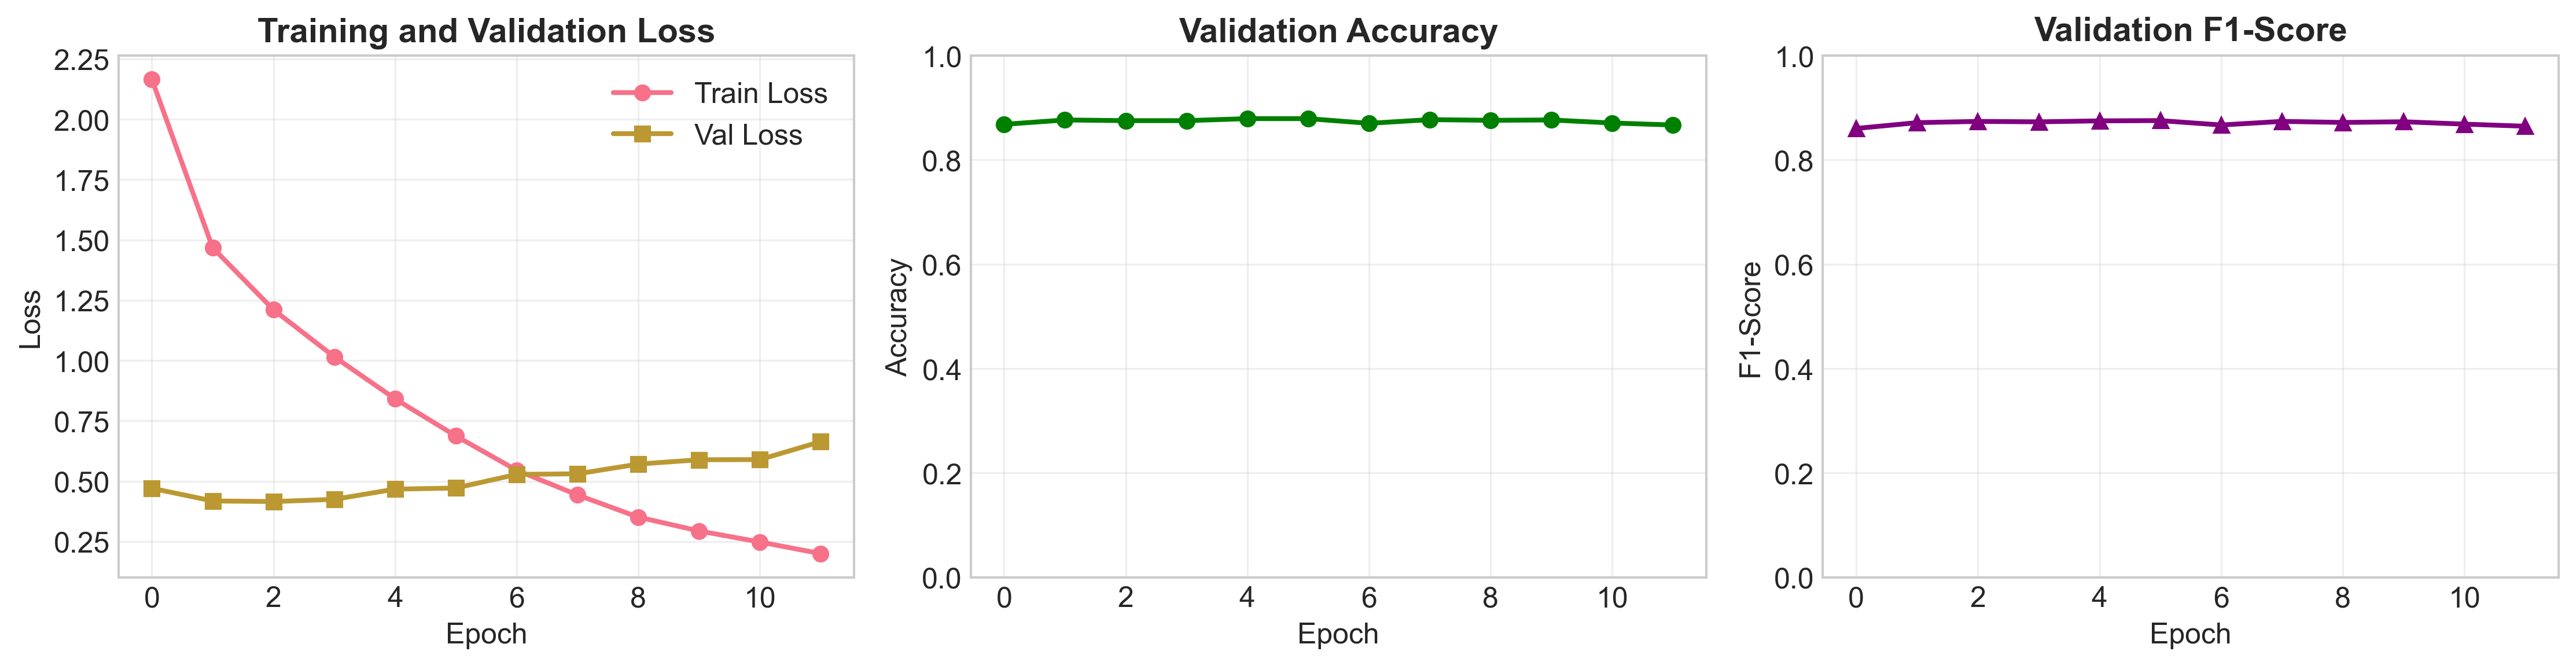

In [10]:
# ============================================================================
# CELL 10: VISUALIZATION - TRAINING HISTORY
# ============================================================================

def plot_training_history(history, save_path=None):
    """Plot training and validation curves"""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    # Training loss
    axes[0].plot(history['train_loss'], label='Train Loss', marker='o', linewidth=2)
    axes[0].plot(history['val_loss'], label='Val Loss', marker='s', linewidth=2)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Training and Validation Loss', fontweight='bold')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Validation accuracy
    axes[1].plot(history['val_accuracy'], label='Val Accuracy', marker='o', 
                color='green', linewidth=2)
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title('Validation Accuracy', fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    axes[1].set_ylim(0, 1)
    
    # Validation F1-score
    axes[2].plot(history['val_f1'], label='Val F1-Score', marker='^', 
                color='purple', linewidth=2)
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('F1-Score')
    axes[2].set_title('Validation F1-Score', fontweight='bold')
    axes[2].grid(True, alpha=0.3)
    axes[2].set_ylim(0, 1)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Training history plot saved to: {save_path}")
    
    plt.show()
    plt.close()

# Plot and save
plot_training_history(
    trainer.history, 
    save_path=f"{Config.VISUALIZATION_DIR}/training_history_mbert.png"
)

In [11]:
# ============================================================================
# CELL 11: VISUALIZATION - CONFUSION MATRICES
# ============================================================================

def plot_confusion_matrix(y_true, y_pred, labels, title, filename, save_dir):
    """Plot confusion matrix with raw and normalized versions"""
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    # Handle NaN in normalized matrix
    cm_normalized = np.nan_to_num(cm_normalized)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Raw counts
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
               xticklabels=labels, yticklabels=labels, ax=axes[0])
    axes[0].set_title(f'{title} - Raw Counts', fontweight='bold')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('Actual')
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
    
    # Normalized
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
               xticklabels=labels, yticklabels=labels, ax=axes[1])
    axes[1].set_title(f'{title} - Normalized', fontweight='bold')
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('Actual')
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
    
    plt.tight_layout()
    plt.savefig(f"{save_dir}/{filename}.png", dpi=300, bbox_inches='tight')
    plt.close()

# Plot confusion matrices
le_primary = preprocessor.le_primary
le_subcat = preprocessor.le_subcat
le_severity = preprocessor.le_severity

# Primary task
plot_confusion_matrix(
    evaluation_results['labels']['primary'],
    evaluation_results['predictions']['primary'],
    le_primary.classes_,
    'Primary Category - mBERT',
    'confusion_primary_mbert',
    Config.VISUALIZATION_DIR
)

# Subcategory task
plot_confusion_matrix(
    evaluation_results['labels']['subcat'],
    evaluation_results['predictions']['subcat'],
    le_subcat.classes_,
    'Subcategory - mBERT',
    'confusion_subcat_mbert',
    Config.VISUALIZATION_DIR
)

# Severity task
plot_confusion_matrix(
    evaluation_results['labels']['severity'],
    evaluation_results['predictions']['severity'],
    le_severity.classes_,
    'Severity - mBERT',
    'confusion_severity_mbert',
    Config.VISUALIZATION_DIR
)

print("✅ Confusion matrices saved successfully")

✅ Confusion matrices saved successfully


Computing t-SNE embeddings...
t-SNE completed. Shape: (1000, 2)
t-SNE plot saved to: visualizations_mbert/tsne_embeddings_mbert.png


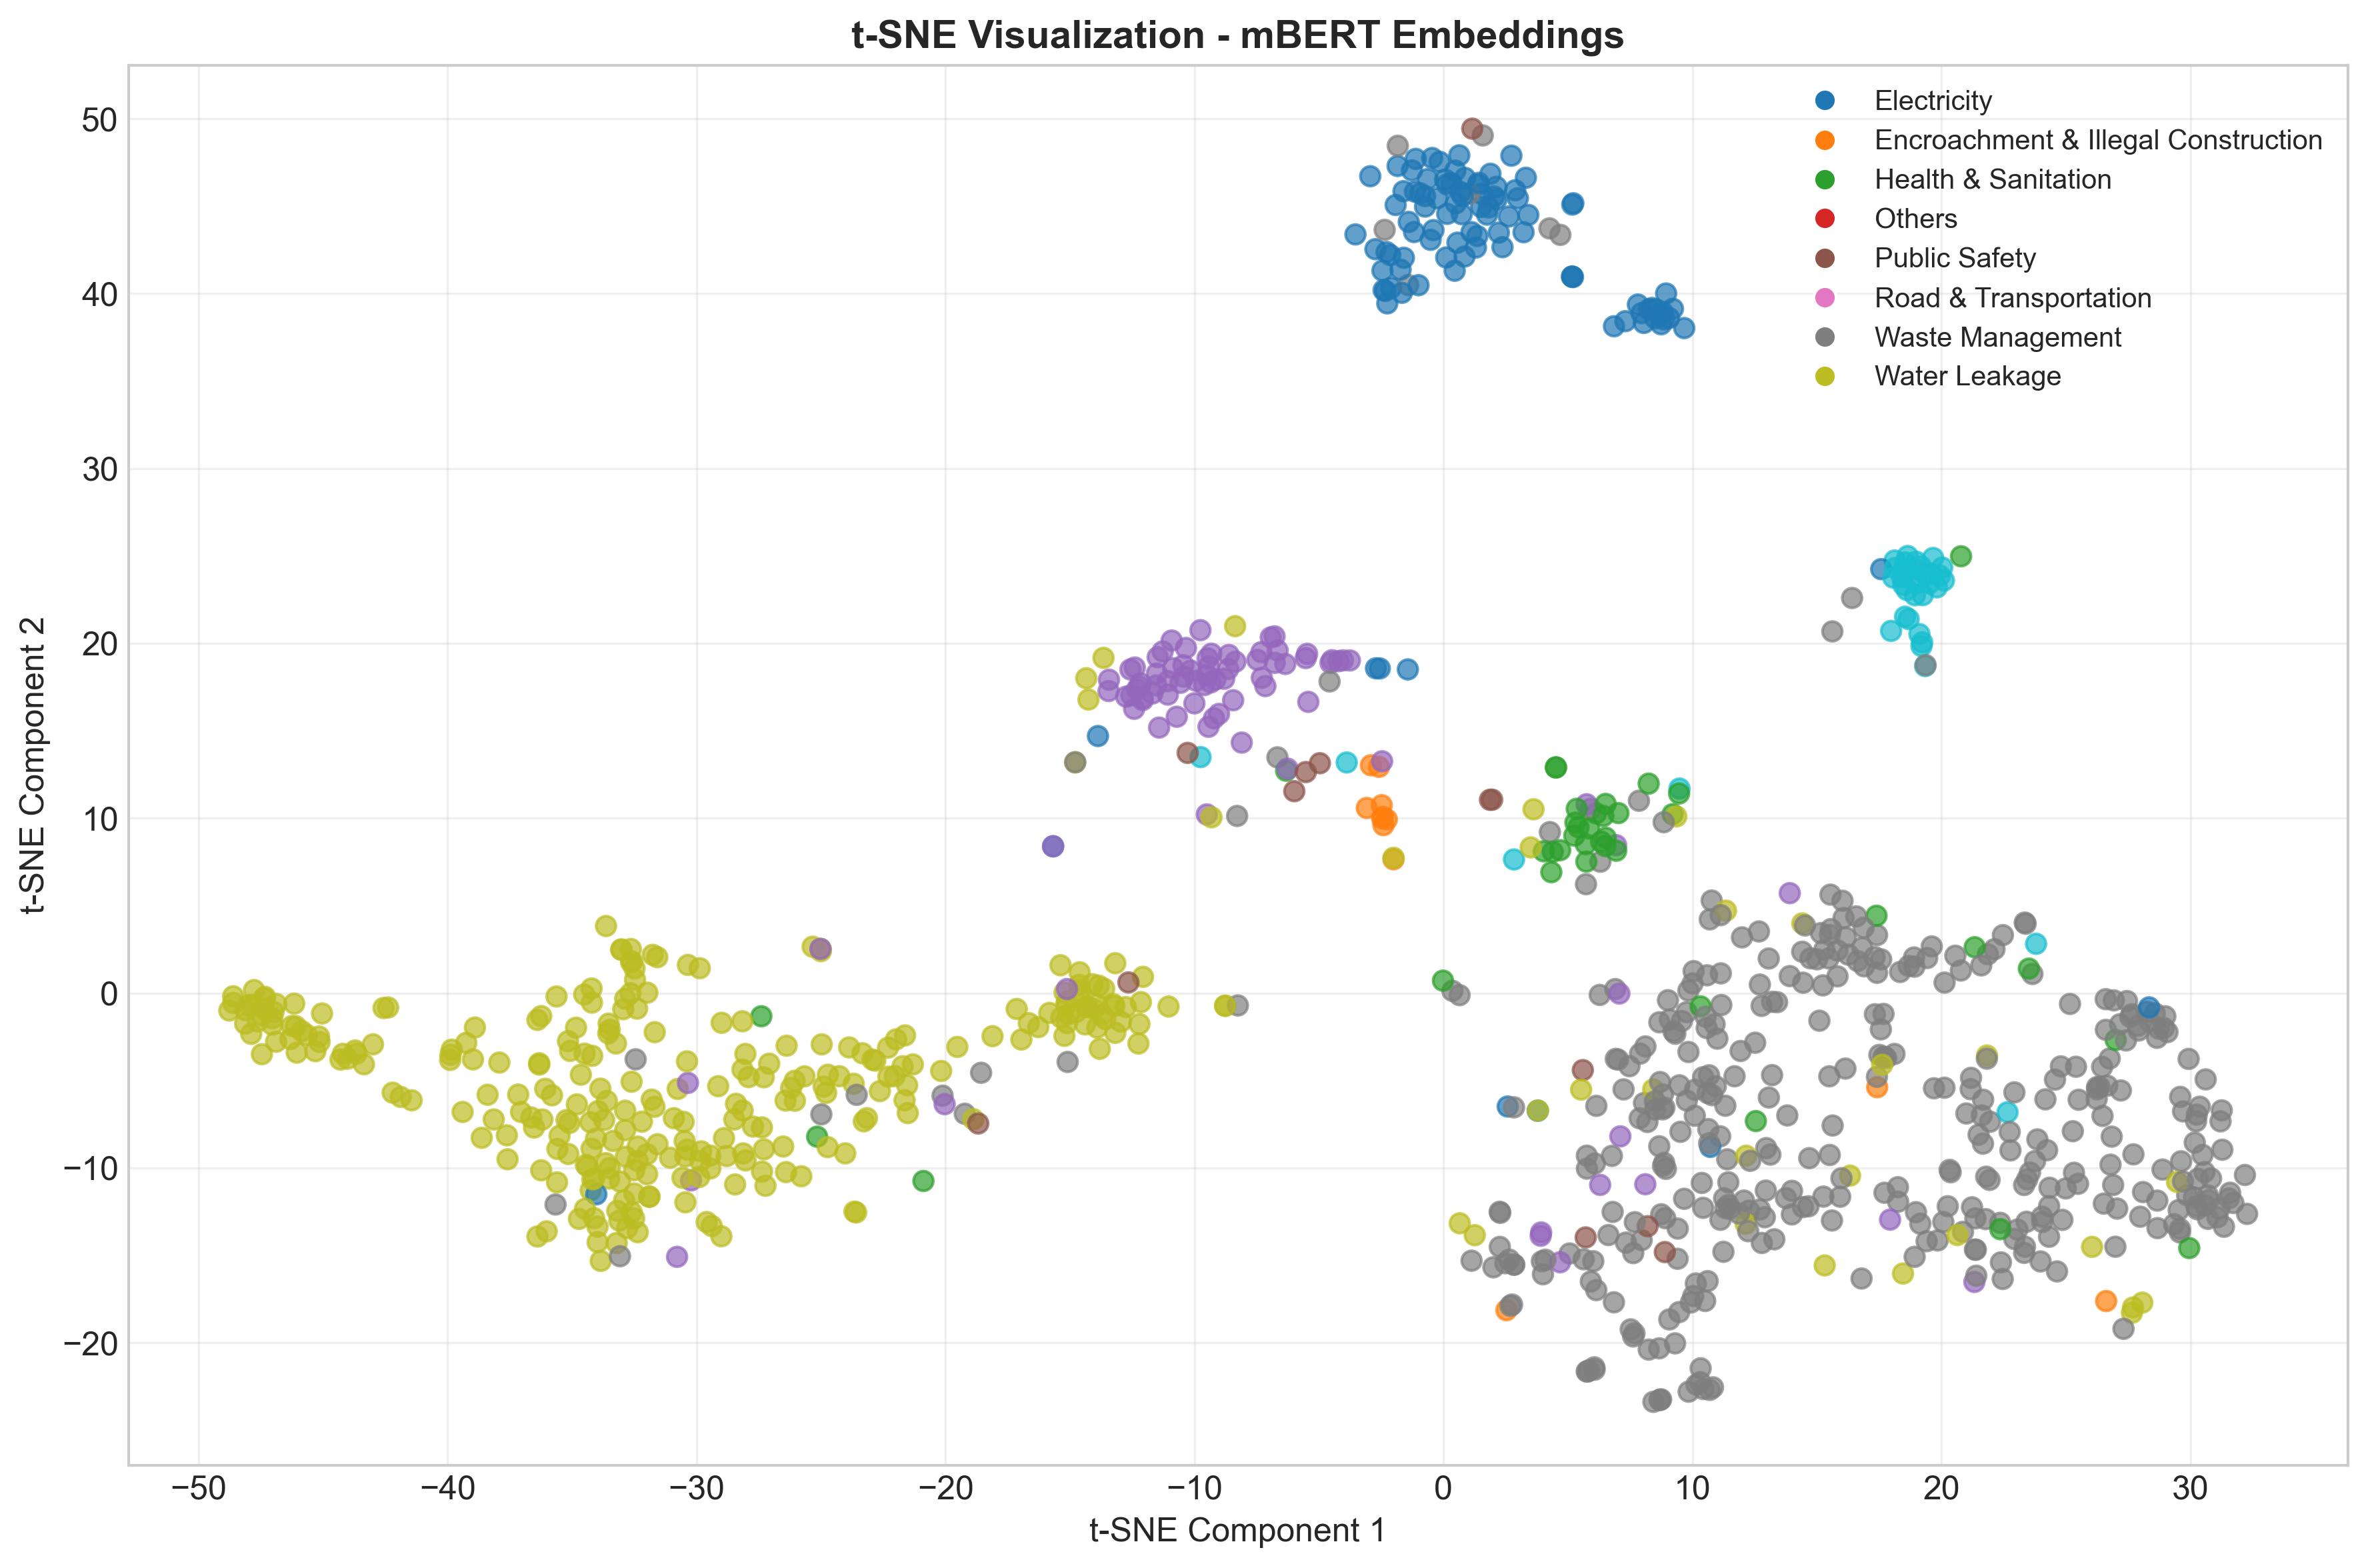

In [12]:
# ============================================================================
# CELL 12: VISUALIZATION - T-SNE EMBEDDINGS
# ============================================================================

def plot_tsne_embeddings(embeddings, labels, label_names, title, save_path=None):
    """Create t-SNE visualization of embeddings"""
    print("Computing t-SNE embeddings...")
    
    # Reduce dimensionality with t-SNE
    tsne = TSNE(
        n_components=2, 
        random_state=Config.SEED, 
        perplexity=30,
        max_iter=1000
    )
    embeddings_2d = tsne.fit_transform(embeddings)
    
    print(f"t-SNE completed. Shape: {embeddings_2d.shape}")
    
    # Create plot
    fig, ax = plt.subplots(figsize=(12, 8))
    
    scatter = ax.scatter(
        embeddings_2d[:, 0], 
        embeddings_2d[:, 1],
        c=labels, 
        cmap='tab10', 
        alpha=0.7, 
        s=50
    )
    
    ax.set_title(f't-SNE Visualization - {title}', fontsize=14, fontweight='bold')
    ax.set_xlabel('t-SNE Component 1', fontsize=12)
    ax.set_ylabel('t-SNE Component 2', fontsize=12)
    ax.grid(True, alpha=0.3)
    
    # Create legend
    legend_elements = []
    for i, name in enumerate(label_names):
        legend_elements.append(
            plt.Line2D([0], [0], marker='o', color='w',
                      markerfacecolor=scatter.cmap(i/len(label_names)),
                      label=name, markersize=8)
        )
    ax.legend(handles=legend_elements, loc='best', fontsize=10)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"t-SNE plot saved to: {save_path}")
    
    plt.show()
    plt.close()

# Get embeddings and labels
embeddings = evaluation_results['embeddings']
labels = evaluation_results['labels']['primary']

# Sample if too many points
if len(embeddings) > 1000:
    idx = np.random.choice(len(embeddings), 1000, replace=False)
    embeddings = embeddings[idx]
    labels = np.array(labels)[idx]

# Plot t-SNE
plot_tsne_embeddings(
    embeddings,
    labels,
    le_primary.classes_,
    'mBERT Embeddings',
    save_path=f"{Config.VISUALIZATION_DIR}/tsne_embeddings_mbert.png"
)

Sentiment analysis plot saved to: visualizations_mbert/sentiment_severity_analysis_mbert.png


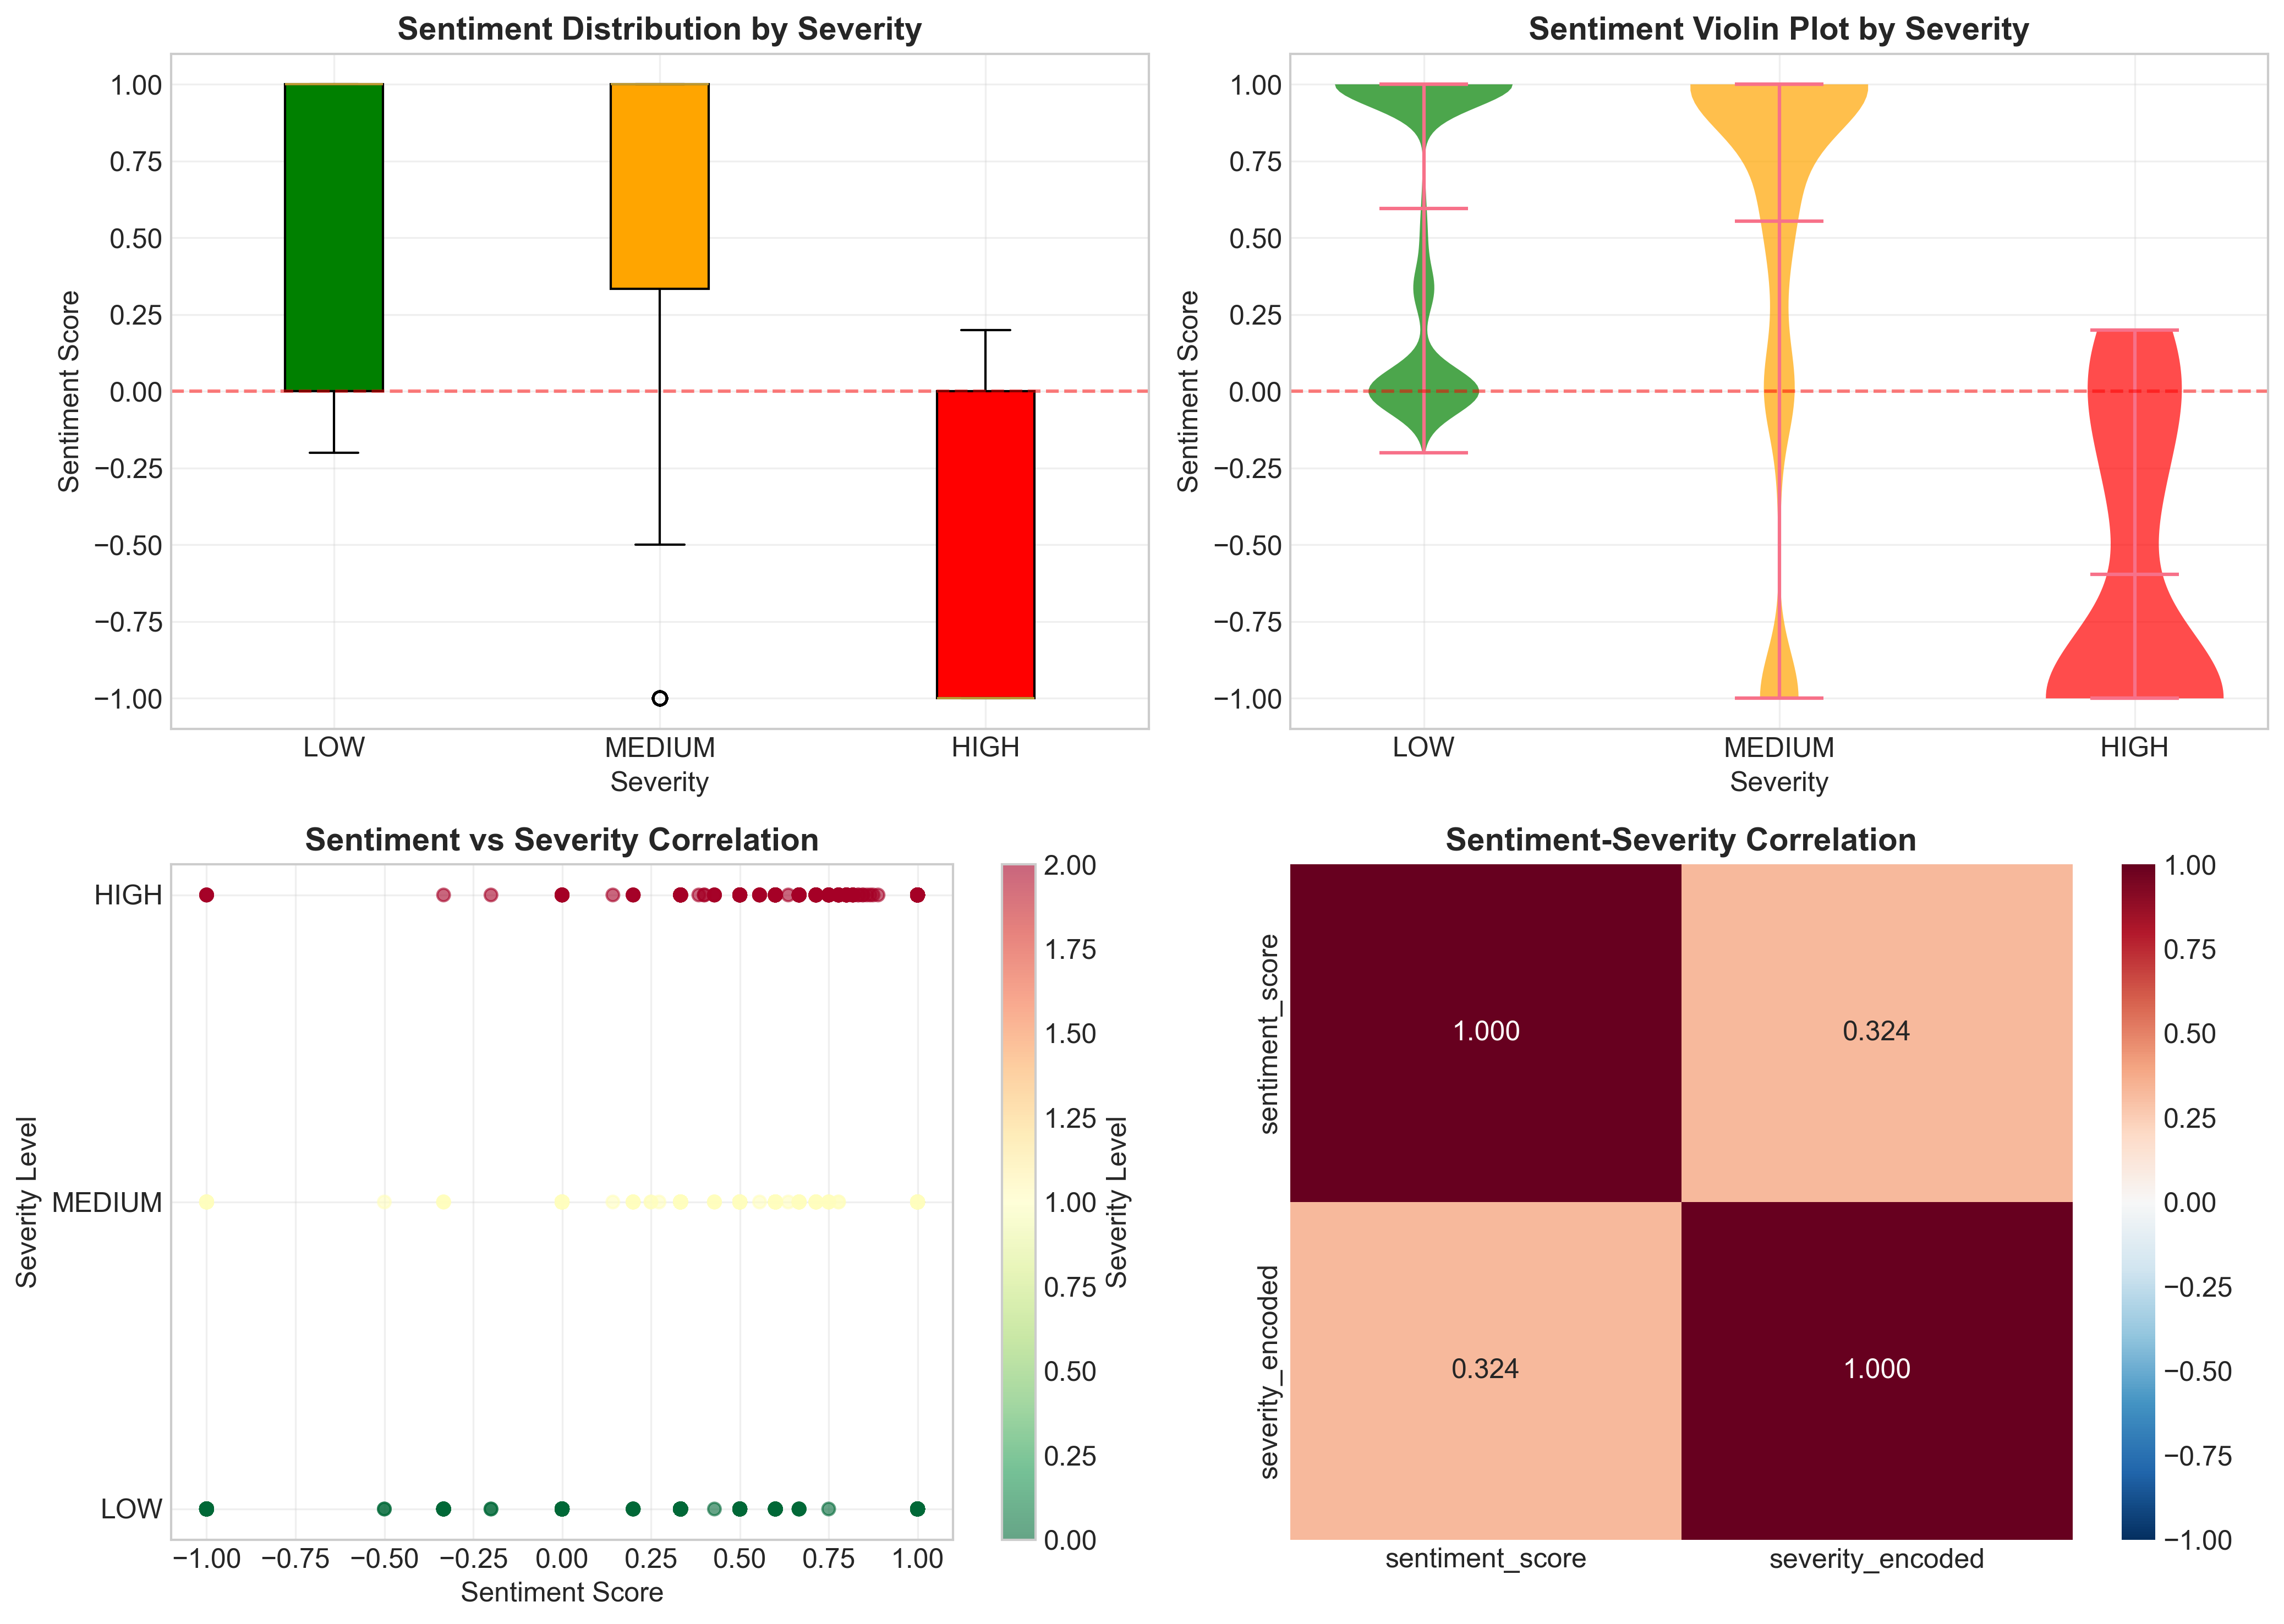

In [13]:
# ============================================================================
# CELL 13: VISUALIZATION - SENTIMENT VS SEVERITY ANALYSIS
# ============================================================================

def plot_sentiment_severity_analysis(df, save_path=None):
    """Analyze relationship between sentiment and severity"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    severity_order = ['LOW', 'MEDIUM', 'HIGH']
    colors = ['green', 'orange', 'red']
    
    # 1. Sentiment distribution by severity
    sentiment_by_severity = [
        df[df['enhanced_severity_label'] == s]['sentiment_score'].values 
        for s in severity_order
    ]
    
    # Box plot
    bp = axes[0, 0].boxplot(sentiment_by_severity, labels=severity_order, 
                           patch_artist=True)
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
    axes[0, 0].axhline(y=0, color='red', linestyle='--', alpha=0.5)
    axes[0, 0].set_xlabel('Severity', fontsize=12)
    axes[0, 0].set_ylabel('Sentiment Score', fontsize=12)
    axes[0, 0].set_title('Sentiment Distribution by Severity', fontweight='bold')
    axes[0, 0].grid(True, alpha=0.3)
    
    # 2. Violin plot
    parts = axes[0, 1].violinplot(sentiment_by_severity, positions=range(len(severity_order)), 
                                 showmeans=True, showmedians=True)
    for i, pc in enumerate(parts['bodies']):
        pc.set_facecolor(colors[i])
        pc.set_alpha(0.7)
    axes[0, 1].set_xticks(range(len(severity_order)))
    axes[0, 1].set_xticklabels(severity_order)
    axes[0, 1].axhline(y=0, color='red', linestyle='--', alpha=0.5)
    axes[0, 1].set_xlabel('Severity', fontsize=12)
    axes[0, 1].set_ylabel('Sentiment Score', fontsize=12)
    axes[0, 1].set_title('Sentiment Violin Plot by Severity', fontweight='bold')
    axes[0, 1].grid(True, alpha=0.3)
    
    # 3. Scatter plot
    scatter = axes[1, 0].scatter(
        df['sentiment_score'], 
        df['severity_encoded'],
        c=df['severity_encoded'],
        cmap='RdYlGn_r',
        alpha=0.6,
        s=30
    )
    axes[1, 0].set_xlabel('Sentiment Score', fontsize=12)
    axes[1, 0].set_ylabel('Severity Level', fontsize=12)
    axes[1, 0].set_yticks([0, 1, 2])
    axes[1, 0].set_yticklabels(['LOW', 'MEDIUM', 'HIGH'])
    axes[1, 0].set_title('Sentiment vs Severity Correlation', fontweight='bold')
    axes[1, 0].grid(True, alpha=0.3)
    plt.colorbar(scatter, label='Severity Level', ax=axes[1, 0])
    
    # 4. Correlation heatmap
    correlation_data = df[['sentiment_score', 'severity_encoded']].corr()
    sns.heatmap(correlation_data, annot=True, fmt='.3f', cmap='RdBu_r',
               center=0, vmin=-1, vmax=1, ax=axes[1, 1])
    axes[1, 1].set_title('Sentiment-Severity Correlation', fontweight='bold')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Sentiment analysis plot saved to: {save_path}")
    
    plt.show()
    plt.close()

# Plot sentiment analysis
plot_sentiment_severity_analysis(
    train_df,
    save_path=f"{Config.VISUALIZATION_DIR}/sentiment_severity_analysis_mbert.png"
)

Class distribution plot saved to: visualizations_mbert/class_distribution_mbert.png


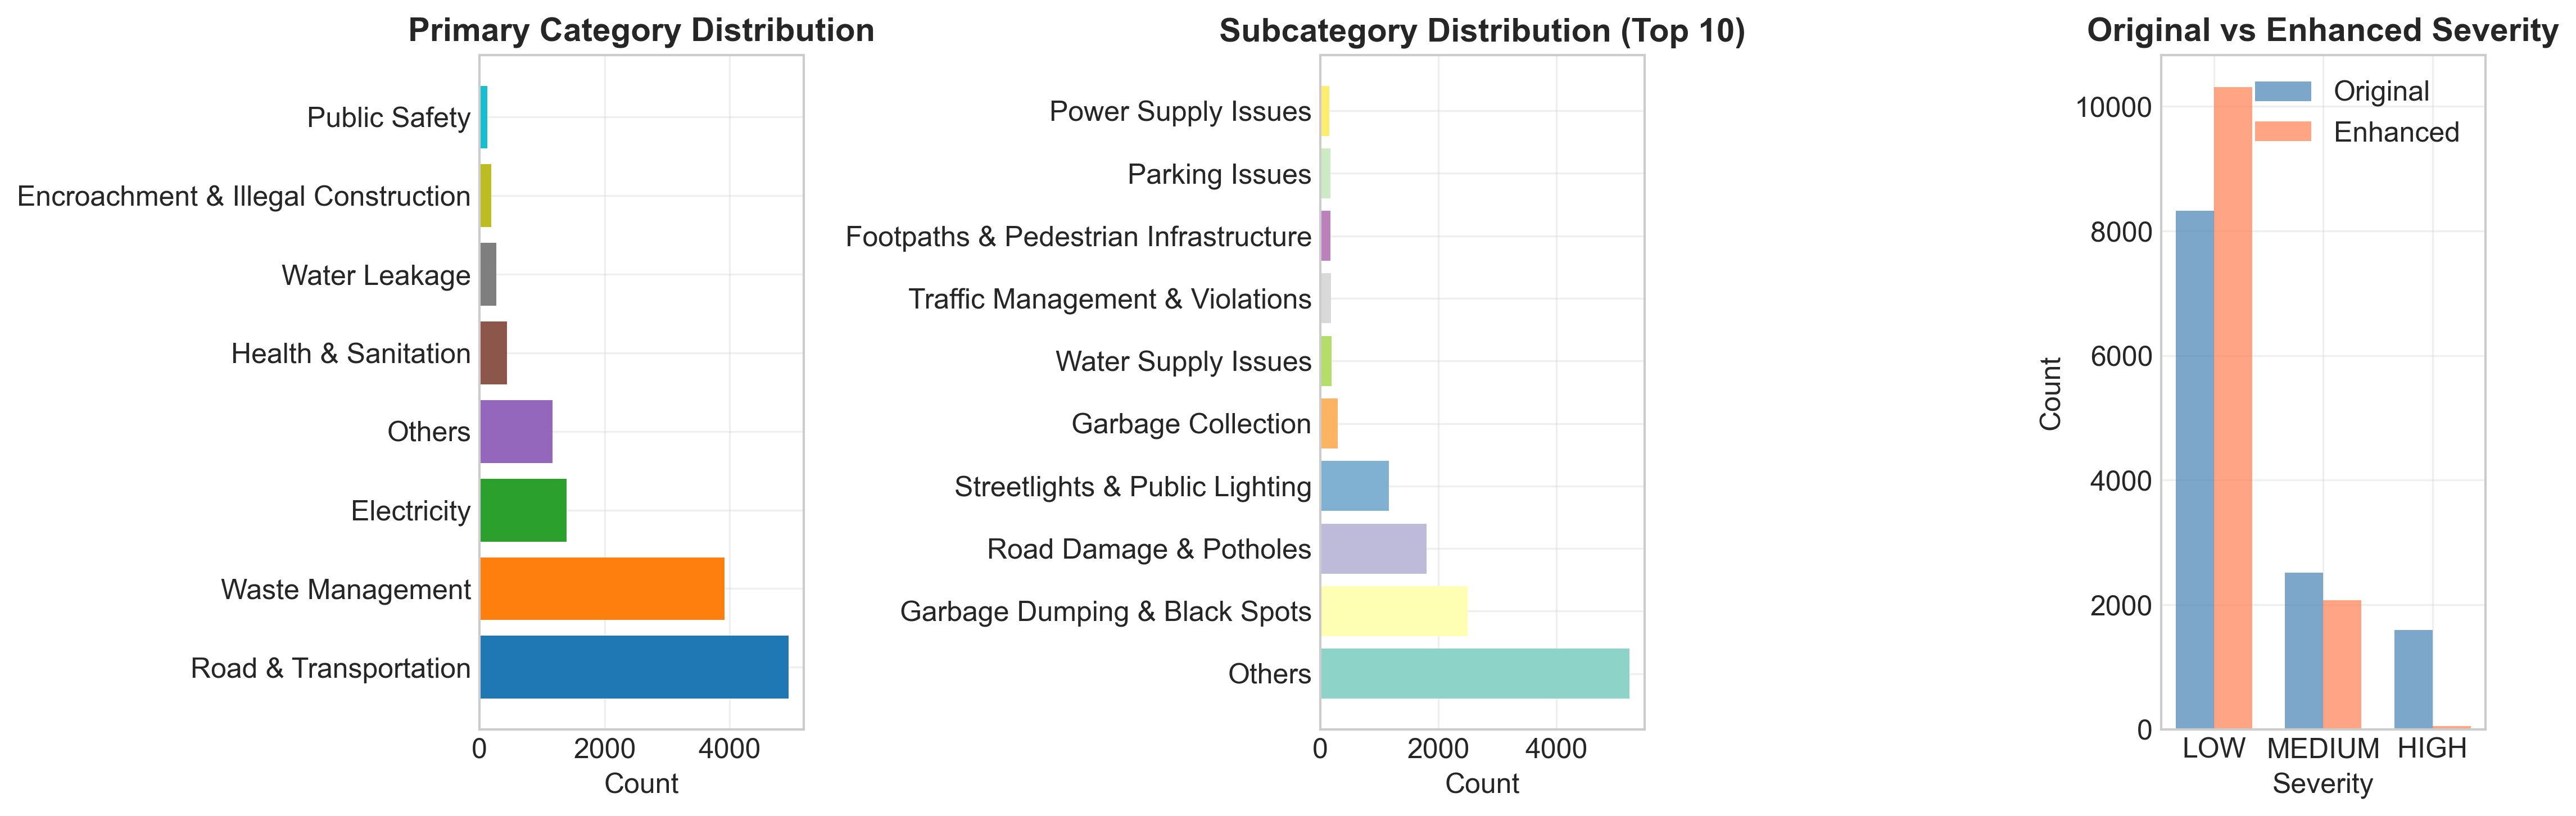

In [14]:
# ============================================================================
# CELL 14: VISUALIZATION - CLASS DISTRIBUTION
# ============================================================================

def plot_class_distribution(df, save_path=None):
    """Plot class distribution for all tasks"""
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # 1. Primary category distribution
    primary_counts = df['category_primary'].value_counts()
    colors = plt.cm.tab10(np.linspace(0, 1, len(primary_counts)))
    axes[0].barh(primary_counts.index, primary_counts.values, color=colors)
    axes[0].set_xlabel('Count', fontsize=12)
    axes[0].set_title('Primary Category Distribution', fontweight='bold')
    axes[0].grid(True, alpha=0.3)
    
    # 2. Subcategory distribution (top 10)
    subcat_counts = df['category_secondary'].value_counts().head(10)
    colors = plt.cm.Set3(np.linspace(0, 1, len(subcat_counts)))
    axes[1].barh(subcat_counts.index, subcat_counts.values, color=colors)
    axes[1].set_xlabel('Count', fontsize=12)
    axes[1].set_title('Subcategory Distribution (Top 10)', fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    
    # 3. Severity distribution (original vs enhanced)
    original_severity = df['severity'].value_counts()
    enhanced_severity = df['enhanced_severity_label'].value_counts()
    
    severity_order = ['LOW', 'MEDIUM', 'HIGH']
    original_counts = [original_severity.get(s, 0) for s in severity_order]
    enhanced_counts = [enhanced_severity.get(s, 0) for s in severity_order]
    
    x = np.arange(len(severity_order))
    width = 0.35
    
    bars1 = axes[2].bar(x - width/2, original_counts, width, label='Original', 
                       color='steelblue', alpha=0.7)
    bars2 = axes[2].bar(x + width/2, enhanced_counts, width, label='Enhanced',
                       color='coral', alpha=0.7)
    
    axes[2].set_xlabel('Severity', fontsize=12)
    axes[2].set_ylabel('Count', fontsize=12)
    axes[2].set_title('Original vs Enhanced Severity', fontweight='bold')
    axes[2].set_xticks(x)
    axes[2].set_xticklabels(severity_order)
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Class distribution plot saved to: {save_path}")
    
    plt.show()
    plt.close()

# Plot class distribution
plot_class_distribution(
    train_df,
    save_path=f"{Config.VISUALIZATION_DIR}/class_distribution_mbert.png"
)

In [15]:
# ============================================================================
# CELL 15: CLASSIFICATION REPORTS
# ============================================================================

def generate_classification_reports(evaluation_results, preprocessor):
    """Generate and print classification reports"""
    
    le_primary = preprocessor.le_primary
    le_subcat = preprocessor.le_subcat
    le_severity = preprocessor.le_severity
    
    # Primary task
    print("\n" + "="*70)
    print("CLASSIFICATION REPORT - PRIMARY CATEGORY (mBERT)")
    print("="*70)
    print(classification_report(
        evaluation_results['labels']['primary'],
        evaluation_results['predictions']['primary'],
        target_names=le_primary.classes_,
        digits=4
    ))
    
    # Subcategory task
    print("\n" + "="*70)
    print("CLASSIFICATION REPORT - SUBCATEGORY (mBERT)")
    print("="*70)
    print(classification_report(
        evaluation_results['labels']['subcat'],
        evaluation_results['predictions']['subcat'],
        target_names=le_subcat.classes_,
        digits=4
    ))
    
    # Severity task
    print("\n" + "="*70)
    print("CLASSIFICATION REPORT - SEVERITY (mBERT)")
    print("="*70)
    print(classification_report(
        evaluation_results['labels']['severity'],
        evaluation_results['predictions']['severity'],
        target_names=le_severity.classes_,
        digits=4
    ))

# Generate classification reports
generate_classification_reports(evaluation_results, preprocessor)


CLASSIFICATION REPORT - PRIMARY CATEGORY (mBERT)
                                     precision    recall  f1-score   support

                        Electricity     0.9096    0.9207    0.9152       164
Encroachment & Illegal Construction     0.8333    0.6000    0.6977        25
                Health & Sanitation     0.6349    0.6667    0.6504        60
                             Others     0.7920    0.7444    0.7674       133
                      Public Safety     0.4286    0.3158    0.3636        19
              Road & Transportation     0.8716    0.9277    0.8988       622
                   Waste Management     0.9289    0.8832    0.9055       488
                      Water Leakage     0.8409    0.8222    0.8315        45

                           accuracy                         0.8715      1556
                          macro avg     0.7800    0.7351    0.7537      1556
                       weighted avg     0.8707    0.8715    0.8701      1556


CLASSIFICATION REPORT 

ValueError: Number of classes, 24, does not match size of target_names, 27. Try specifying the labels parameter

In [ ]:
# ============================================================================
# CELL 16: STATISTICAL VALIDATION
# ============================================================================

def perform_statistical_tests(evaluation_results, preprocessor):
    """Perform statistical tests on predictions"""
    
    print("\n" + "="*70)
    print("STATISTICAL VALIDATION - MBERT")
    print("="*70)
    
    # 1. Confidence intervals for accuracy
    def calculate_confidence_interval(accuracy, n, confidence=0.95):
        """Calculate confidence interval for accuracy"""
        se = np.sqrt((accuracy * (1 - accuracy)) / n)
        z_score = 1.96  # 95% confidence
        ci_lower = accuracy - z_score * se
        ci_upper = accuracy + z_score * se
        return ci_lower, ci_upper
    
    n_test = len(test_df)
    
    print("\n1. Confidence Intervals (95%):")
    for task, metrics in evaluation_results['metrics'].items():
        acc = metrics['accuracy']
        ci_lower, ci_upper = calculate_confidence_interval(acc, n_test)
        print(f"  {task.capitalize()} Accuracy: {acc:.4f} ± {acc - ci_lower:.4f}")
        print(f"    CI: [{ci_lower:.4f}, {ci_upper:.4f}]")
    
    # 2. Per-class performance statistics
    print("\n2. Per-class Performance Statistics:")
    
    for task_name, labels_key in [('Primary', 'primary'), ('Subcategory', 'subcat'), ('Severity', 'severity')]:
        print(f"\n  {task_name}:")
        
        y_true = evaluation_results['labels'][labels_key]
        y_pred = evaluation_results['predictions'][labels_key]
        
        # Per-class metrics
        precision, recall, f1, support = precision_recall_fscore_support(
            y_true, y_pred, average=None
        )
        
        # Find best and worst performing classes
        f1_with_class = list(zip(f1, 
                                 preprocessor.le_primary.classes_ if labels_key == 'primary' 
                                 else preprocessor.le_subcat.classes_ if labels_key == 'subcat'
                                 else preprocessor.le_severity.classes_))
        f1_with_class.sort(reverse=True)
        
        print(f"    Best performing class: {f1_with_class[0][1]} (F1: {f1_with_class[0][0]:.4f})")
        print(f"    Worst performing class: {f1_with_class[-1][1]} (F1: {f1_with_class[-1][0]:.4f})")
        print(f"    Mean F1: {np.mean(f1):.4f} ± {np.std(f1):.4f}")
    
    # 3. Model stability
    print("\n3. Model Stability Analysis:")
    
    # Calculate metrics over epochs
    accuracy_values = trainer.history['val_accuracy']
    f1_values = trainer.history['val_f1']
    
    print(f"  Validation Accuracy: Mean={np.mean(accuracy_values):.4f} ± {np.std(accuracy_values):.4f}")
    print(f"  Validation F1-Score: Mean={np.mean(f1_values):.4f} ± {np.std(f1_values):.4f}")
    
    # Check for overfitting
    final_train_loss = trainer.history['train_loss'][-1]
    final_val_loss = trainer.history['val_loss'][-1]
    loss_ratio = final_val_loss / final_train_loss
    
    if loss_ratio < 1.2:
        print(f"  ✅ No significant overfitting (Loss ratio: {loss_ratio:.2f})")
    else:
        print(f"  ⚠️ Possible overfitting (Loss ratio: {loss_ratio:.2f})")

# Perform statistical tests
perform_statistical_tests(evaluation_results, preprocessor)

In [ ]:
# ============================================================================
# CELL 17: INFERENCE FUNCTION
# ============================================================================

def predict_complaint(text, model, tokenizer, preprocessor, device):
    """
    Predict complaint category, subcategory, and severity
    
    Args:
        text: Input complaint text
        model: Trained model
        tokenizer: Tokenizer
        preprocessor: DataPreprocessor instance
        device: Device to run inference on
    
    Returns:
        Dictionary with predictions
    """
    # Compute sentiment
    sentiment = preprocessor.compute_sentiment_score(text)
    
    # Tokenize
    enc = tokenizer(
        text,
        truncation=True,
        padding="max_length",
        max_length=Config.MAX_LENGTH,
        return_tensors="pt"
    )
    
    input_ids = enc["input_ids"].to(device)
    attention_mask = enc["attention_mask"].to(device)
    sentiment_tensor = torch.tensor([sentiment], dtype=torch.float).to(device)
    
    # Predict
    model.eval()
    with torch.no_grad():
        p1, p2, p3 = model(input_ids, attention_mask, sentiment_tensor)
    
    # Convert predictions to labels
    primary = preprocessor.le_primary.inverse_transform(
        [torch.argmax(p1).item()]
    )[0]
    subcat = preprocessor.le_subcat.inverse_transform(
        [torch.argmax(p2).item()]
    )[0]
    severity = preprocessor.le_severity.inverse_transform(
        [torch.argmax(p3).item()]
    )[0]
    
    # Get confidence scores
    primary_conf = torch.softmax(p1, dim=1).max().item()
    subcat_conf = torch.softmax(p2, dim=1).max().item()
    severity_conf = torch.softmax(p3, dim=1).max().item()
    
    return {
        'primary_category': primary,
        'subcategory': subcat,
        'severity': severity,
        'sentiment_score': sentiment,
        'confidence': {
            'primary': primary_conf,
            'subcategory': subcat_conf,
            'severity': severity_conf
        }
    }

# Test inference
test_texts = [
    "Garbage not collected in my area for last 5 days. Bad smell everywhere! Very urgent!",
    "There is a very big pothole on the main road, my car got damaged",
    "Water leakage in our building, please fix immediately, it's an emergency!",
    "Thank you for fixing the streetlight in our area, it's working now.",
    "Streetlights not working on my street for 3 days, very dangerous at night",
    "The garbage bins are overflowing and spreading foul smell in the entire colony"
]

print("\n" + "="*70)
print("INFERENCE DEMO - MBERT")
print("="*70)

for i, text in enumerate(test_texts, 1):
    print(f"\nText {i}: {text}")
    print("-" * 50)
    
    result = predict_complaint(
        text, model, tokenizer, preprocessor, Config.DEVICE
    )
    
    print(f"Primary Category: {result['primary_category']}")
    print(f"Subcategory: {result['subcategory']}")
    print(f"Severity: {result['severity']}")
    print(f"Sentiment Score: {result['sentiment_score']:.3f}")
    print(f"Confidence:")
    print(f"  Primary: {result['confidence']['primary']:.4f}")
    print(f"  Subcategory: {result['confidence']['subcategory']:.4f}")
    print(f"  Severity: {result['confidence']['severity']:.4f}")

In [ ]:
# ============================================================================
# CELL 18: SUMMARY REPORT
# ============================================================================

def generate_summary_report(model, evaluation_results, preprocessor, trainer):
    """Generate comprehensive summary report"""
    
    print("\n" + "="*70)
    print("MBERT MULTI-TASK COMPLAINT CLASSIFICATION - SUMMARY REPORT")
    print("="*70)
    
    print("\n1. DATASET STATISTICS:")
    print(f"   Training samples: {len(train_df)}")
    print(f"   Validation samples: {len(dev_df)}")
    print(f"   Test samples: {len(test_df)}")
    print(f"   Primary categories: {len(preprocessor.le_primary.classes_)}")
    print(f"   Subcategories: {len(preprocessor.le_subcat.classes_)}")
    print(f"   Severity levels: {len(preprocessor.le_severity.classes_)}")
    
    print("\n2. MODEL ARCHITECTURE:")
    print(f"   Base Model: {Config.MBERT_PATH}")
    print(f"   Hidden Size: {base_model.config.hidden_size}")
    print(f"   Total Parameters: {sum(p.numel() for p in model.parameters()):,}")
    print(f"   Dropout Rate: {Config.DROPOUT}")
    print(f"   Max Sequence Length: {Config.MAX_LENGTH}")
    
    print("\n3. TRAINING DETAILS:")
    print(f"   Epochs: {Config.EPOCHS}")
    print(f"   Batch Size: {Config.BATCH_SIZE}")
    print(f"   Learning Rate: {Config.LEARNING_RATE}")
    print(f"   Optimizer: AdamW")
    print(f"   Device: {Config.DEVICE}")
    
    print("\n4. PERFORMANCE METRICS (Test Set):")
    for task, metrics in evaluation_results['metrics'].items():
        print(f"\n   {task.upper()}:")
        for metric_name, value in metrics.items():
            print(f"     {metric_name}: {value:.4f}")
    
    print("\n5. MODEL STABILITY:")
    print(f"   Final Train Loss: {trainer.history['train_loss'][-1]:.4f}")
    print(f"   Final Val Loss: {trainer.history['val_loss'][-1]:.4f}")
    print(f"   Best Val Accuracy: {max(trainer.history['val_accuracy']):.4f}")
    print(f"   Best Val F1-Score: {max(trainer.history['val_f1']):.4f}")
    
    print("\n6. VISUALIZATIONS SAVED:")
    print(f"   - Training History: {Config.VISUALIZATION_DIR}/training_history_mbert.png")
    print(f"   - Confusion Matrices: {Config.VISUALIZATION_DIR}/confusion_*_mbert.png")
    print(f"   - t-SNE Embeddings: {Config.VISUALIZATION_DIR}/tsne_embeddings_mbert.png")
    print(f"   - Sentiment Analysis: {Config.VISUALIZATION_DIR}/sentiment_severity_analysis_mbert.png")
    print(f"   - Class Distribution: {Config.VISUALIZATION_DIR}/class_distribution_mbert.png")
    
    print("\n7. SAVED FILES:")
    print(f"   - Model: {Config.MODEL_DIR}/mbert_multitask_model.pt")
    print(f"   - Encoders: {Config.MODEL_DIR}/le_*.pkl")
    
    print("\n" + "="*70)
    print("END OF REPORT")
    print("="*70)

# Generate summary report
generate_summary_report(
    model, evaluation_results, preprocessor, trainer
)

In [ ]:
# ============================================================================
# CELL 19: SAVE RESULTS FOR PUBLICATION
# ============================================================================

def save_publication_results(evaluation_results, preprocessor, trainer, save_dir):
    """Save results in format suitable for publication tables"""
    
    print("\nSaving results for publication...")
    
    # 1. Save metrics as CSV
    metrics_df = pd.DataFrame()
    
    for task, metrics in evaluation_results['metrics'].items():
        row = pd.DataFrame([metrics], index=[task])
        metrics_df = pd.concat([metrics_df, row])
    
    metrics_df.to_csv(f"{save_dir}/test_metrics_mbert.csv")
    print(f"Metrics saved to: {save_dir}/test_metrics_mbert.csv")
    
    # 2. Save training history
    history_df = pd.DataFrame(trainer.history)
    history_df.to_csv(f"{save_dir}/training_history_mbert.csv")
    print(f"Training history saved to: {save_dir}/training_history_mbert.csv")
    
    # 3. Save predictions
    predictions_df = pd.DataFrame({
        'true_primary': evaluation_results['labels']['primary'],
        'pred_primary': evaluation_results['predictions']['primary'],
        'true_subcat': evaluation_results['labels']['subcat'],
        'pred_subcat': evaluation_results['predictions']['subcat'],
        'true_severity': evaluation_results['labels']['severity'],
        'pred_severity': evaluation_results['predictions']['severity']
    })
    predictions_df.to_csv(f"{save_dir}/test_predictions_mbert.csv")
    print(f"Predictions saved to: {save_dir}/test_predictions_mbert.csv")
    
    # 4. Save classification reports
    with open(f"{save_dir}/classification_report_mbert.txt", 'w') as f:
        f.write("CLASSIFICATION REPORTS - MBERT\n")
        f.write("="*70 + "\n\n")
        
        # Primary
        f.write("PRIMARY CATEGORY\n")
        f.write("-"*50 + "\n")
        f.write(classification_report(
            evaluation_results['labels']['primary'],
            evaluation_results['predictions']['primary'],
            target_names=preprocessor.le_primary.classes_
        ))
        f.write("\n\n")
        
        # Subcategory
        f.write("SUBCATEGORY\n")
        f.write("-"*50 + "\n")
        f.write(classification_report(
            evaluation_results['labels']['subcat'],
            evaluation_results['predictions']['subcat'],
            target_names=preprocessor.le_subcat.classes_
        ))
        f.write("\n\n")
        
        # Severity
        f.write("SEVERITY\n")
        f.write("-"*50 + "\n")
        f.write(classification_report(
            evaluation_results['labels']['severity'],
            evaluation_results['predictions']['severity'],
            target_names=preprocessor.le_severity.classes_
        ))
    
    print(f"Classification reports saved to: {save_dir}/classification_report_mbert.txt")
    
    print("\n✅ All publication results saved successfully")

# Save results
save_publication_results(
    evaluation_results, 
    preprocessor, 
    trainer,
    Config.OUTPUT_DIR
)

In [ ]:
# ============================================================================
# CELL 20: COMPLETE PIPELINE EXECUTION - MBERT
# ============================================================================

print("\n" + "="*70)
print("MBERT MULTI-TASK CLASSIFICATION PIPELINE")
print("="*70)

# Step 1: Setup completed in previous cells

# Step 2: Data processing completed in Cell 3

# Step 3: Model creation completed in Cells 5-6

# Step 4: Training completed in Cell 8

# Step 5: Evaluation completed in Cell 9

# Step 6: Visualizations completed in Cells 10-14

# Step 7: Statistical validation completed in Cell 16

# Step 8: Inference completed in Cell 17

# Step 9: Summary completed in Cell 18

print("\n" + "="*70)
print("MBERT PIPELINE COMPLETED SUCCESSFULLY")
print("="*70)
print(f"\nAll results saved to: {Config.OUTPUT_DIR}")
print(f"Model saved to: {Config.MODEL_DIR}")
print(f"Visualizations saved to: {Config.VISUALIZATION_DIR}")